<a href="https://colab.research.google.com/github/Roheya20/Complete-Data-Science-Project/blob/main/Week4_Capstone_Roheya_Touray.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
import numpy as np

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

Week 4 Capstone: Predicting Internship Selection Outcomes

In [ ]:
df = pd.read_csv('cleaned_applicants.csv')

In [ ]:
df.head()

,applicant_id,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status,Domain Original
0,1,Grace Njeri,grace.njeri25@gmail.com,0788963003,Web Development,ALU,2026-05-25,Selected,Web Development
1,2,Fatou Jallow,fatou.jallow44@gmail.com,0788985669,AI,ALU,2026-06-13,Rejected,Machine Learning
2,3,Sara Ahmed,sara.ahmed35@gmail.com,0788982709,Web Development,ALU,2026-06-04,Under Review,Web Development
3,4,Aminata Koroma,aminata.koroma16@gmail.com,0788150626,AI,ALU,2026-05-16,Rejected,AI
4,5,Linda Brown,linda.brown31@gmail.com,0788851138,AI,ALU,2026-05-31,Selected,Machine Learning


In [ ]:
df.shape


(63, 9)

In [ ]:
np.random.seed(42)

In [ ]:
df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))

In [ ]:
df['has_portfolio'] = np.random.choice(['Yes', 'No'], size = len(df), p=[0.4, 0.6])

In [ ]:
df['prior_hackathon_participation'] = np.random.choice(['Yes', 'No'], size = len(df), p=[0.3, 0.7])

In [ ]:
df['statement_quality_score'] = np.random.randint(1, 11, size=len(df))

In [ ]:
df.head()

,applicant_id,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status,Domain Original,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score
0,1,Grace Njeri,grace.njeri25@gmail.com,0788963003,Web Development,ALU,2026-05-25,Selected,Web Development,7,No,Yes,8
1,2,Fatou Jallow,fatou.jallow44@gmail.com,0788985669,AI,ALU,2026-06-13,Rejected,Machine Learning,4,Yes,Yes,1
2,3,Sara Ahmed,sara.ahmed35@gmail.com,0788982709,Web Development,ALU,2026-06-04,Under Review,Web Development,5,No,No,6
3,4,Aminata Koroma,aminata.koroma16@gmail.com,0788150626,AI,ALU,2026-05-16,Rejected,AI,7,No,Yes,8
4,5,Linda Brown,linda.brown31@gmail.com,0788851138,AI,ALU,2026-05-31,Selected,Machine Learning,3,Yes,No,5


In [ ]:
df.shape

(63, 13)

**Note on Simulated Features**

The four additional features(num_skills_listed, has_portfolio, prior_hackathon_participation, and statement_quality_score) were generated using Numpy.

These features are simulated and do not represent actual historical applicant information. They were introduced to provide additional input features for training and evaluating the machine learning models.

In [ ]:
df['has_portfolio'] = df['has_portfolio'].map({'Yes': 1, 'No':0})

In [ ]:
df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({'Yes': 1, 'No':0})

In [ ]:
df['target'] = df['Status'].apply(lambda x: 1 if x == 'Selected' else 0)

In [ ]:
df_model = df[df['Status'] != 'Under Review'].copy()

In [ ]:
df_model = pd.get_dummies(df_model, columns=['Domain Applied'], drop_first=True)

In [ ]:
df_model.head()

,applicant_id,Applicant Name,Email,Phone,University,Application Date,Status,Domain Original,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score,target,Domain Applied_Cybersecurity,Domain Applied_Data Science,Domain Applied_Web Development
0,1,Grace Njeri,grace.njeri25@gmail.com,0788963003,ALU,2026-05-25,Selected,Web Development,7,0,1,8,1,False,False,True
1,2,Fatou Jallow,fatou.jallow44@gmail.com,0788985669,ALU,2026-06-13,Rejected,Machine Learning,4,1,1,1,0,False,False,False
3,4,Aminata Koroma,aminata.koroma16@gmail.com,0788150626,ALU,2026-05-16,Rejected,AI,7,0,1,8,0,False,False,False
4,5,Linda Brown,linda.brown31@gmail.com,0788851138,ALU,2026-05-31,Selected,Machine Learning,3,1,0,5,1,False,False,False
5,6,James Okafor,james.okafor27@gmail.com,0788970640,ALU,2026-05-27,Rejected,Data Science,8,1,1,4,0,False,True,False


In [ ]:
feature_columns = ['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score'] + [col for col in df_model.columns if col.startswith('Domain Applied_')]

In [ ]:
x = df_model[feature_columns]

In [ ]:
y = df_model['target']

**Feature Selection and Justification**

7 features were selected for the model:

**num_skills_listed**: Number of skills listed by the applicant.

**has_portfolio**: Whether the applicant has a portfolio.

**prior_hackathon_participation**: Whether the applicant has participated in hackathons.

**statement_quality_score**: Personal statement quality score.

**Application domain features**: One-hot encoded columns representing Cybersecurity, Data Science, and Web Development. AI is the reference category.

**Excluded Features:**
Applicant Name, Email, Phone, and applicant_id were excluded because they are identifiers, not meaningful predictive features. University, Application Date, and Domain Original were also excluded because they are not needed for this model. Status and target were excluded from the input features to prevent data leakage, since target is what the model is predicting.

Note: The four additional applicant features are simulated, not actual historical information.

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state= 42
)

In [ ]:
print("Training set:", len(x_train), "rows")


Training set: 37 rows


In [ ]:
print("Testing set:", len(x_test), "rows")

Testing set: 10 rows


### Train/Test Split

The dataset was divided into 80% training data and 20% testing data.

- **Training set:** 37 rows.
- **Testing set:** 10 rows.

The training set is used to train the machine learning models, while the testing set evaluates their performance on unseen data.

Since the dataset is relatively small, the test set contains only 10 rows. Therefore, the evaluation results may not be fully representative and should be interpreted with caution.

In [ ]:
model = LogisticRegression(max_iter=1000)


In [ ]:
model.fit(x_train, y_train)


LogisticRegression(max_iter=1000)

In [ ]:
model = DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
model.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
y_pred = model.predict(x_test)

### Model Selection

Logistic Regression was selected because this task involves binary classification: predicting whether an applicant will be Selected (1) or Rejected (0). It is a simple and suitable model for this prediction task.

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

In [ ]:
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 60.00%


In [ ]:
precision = precision_score(y_test, y_pred)

In [ ]:
recall = recall_score(y_test, y_pred)

In [ ]:
print(f"Precision: {precision:.2%}")

Precision: 66.67%


In [ ]:
print(f"Recall: {recall:.2%}")

Recall: 85.71%


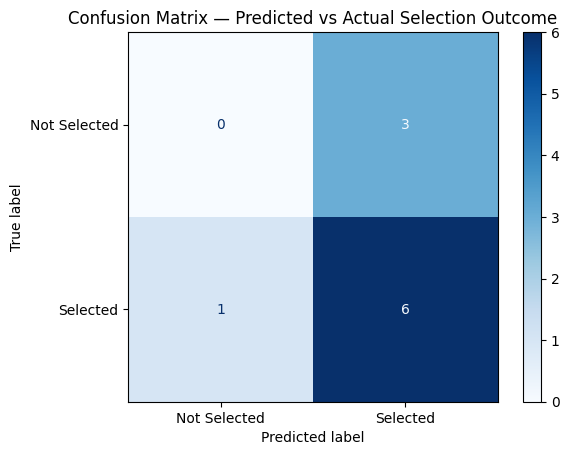

In [ ]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Selected', 'Selected']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix — Predicted vs Actual Selection Outcome')
plt.show()

### Model Evaluation Results

The Logistic Regression model achieved an accuracy of 60.00%, precision of 66.67%, and recall of 85.71%.

The recall score indicates that the model correctly identified most of the applicants who were actually selected. However, its precision shows that some applicants predicted as selected were not actually selected.

Accuracy alone does not provide a complete picture of model performance, so precision, recall, and the confusion matrix are also important for evaluating its predictions.

### 6.3 Model Limitations

1. **Small and simulated dataset:** The dataset contains only 47 confirmed applicants. Four features were artificially generated using NumPy and do not represent real historical applicant behavior.

2. **Limited reliability:** Because the test set is small, the evaluation results may change if the data is split differently. Therefore, these results are illustrative and should not be treated as a guarantee of real-world performance.

3. **Potential bias:** The model may learn and repeat biases from previous selection decisions. For example, it could favor applicants from certain universities if historical decisions unfairly favored those institutions.

4. **Human oversight:** The model should be used as a decision-support tool, not as a replacement for human judgement and applicant review.

Overall, the model's predictions should be interpreted carefully before being considered for real applicant selection.


In [ ]:
print(type(model))

<class 'sklearn.tree._classes.DecisionTreeClassifier'>


In [ ]:
log_model = LogisticRegression(max_iter=1000)


In [ ]:
log_model.fit(x_train, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
coefficients = pd.DataFrame({
    'Feature': x.columns,
    'Coefficient': log_model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print(coefficients)

                          Feature  Coefficient
4    Domain Applied_Cybersecurity     0.951607
1                   has_portfolio     0.757847
5     Domain Applied_Data Science     0.695270
6  Domain Applied_Web Development     0.682602
3         statement_quality_score     0.133242
0               num_skills_listed    -0.114703
2   prior_hackathon_participation    -0.679038


In [ ]:
importance = pd.DataFrame({
    'Feature': x.columns,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

In [ ]:
print(importance)

                          Feature  Importance
3         statement_quality_score    0.515171
1                   has_portfolio    0.193981
0               num_skills_listed    0.145424
2   prior_hackathon_participation    0.145424
4    Domain Applied_Cybersecurity    0.000000
5     Domain Applied_Data Science    0.000000
6  Domain Applied_Web Development    0.000000


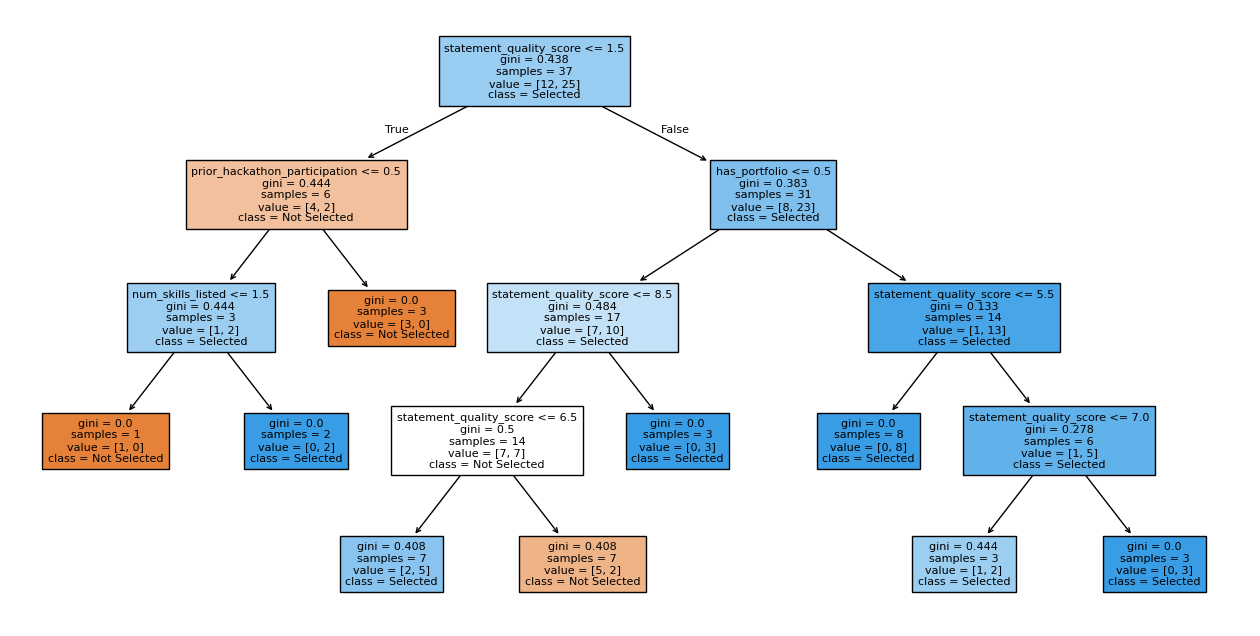

In [ ]:
plt.figure(figsize=(16,8))
plot_tree(model, feature_names=x.columns, class_names=['Not Selected',
'Selected'], filled=True, fontsize=8)
plt.show()

In [ ]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(x_train, y_train)

DecisionTreeClassifier(random_state=42)

### Step 7: Feature Importance and Interpretation

Both Logistic Regression and Decision Tree were examined to understand which features influenced their predictions.

The Logistic Regression coefficients show the direction of each feature's association with selection, while the Decision Tree feature importance scores show which features contributed most to its decisions.

The results help identify the features each model relied on when distinguishing between Selected and Not Selected applicants.

However, these findings describe patterns learned from this particular dataset, not the actual selection criteria used by NextGenLearners. Since some features were simulated and the dataset is small, the findings would need to be validated using real historical applicant data.

## Executive Summary

**What I did:**

I built two simple prediction models using applicant data to explore the factors that may influence selection into the NextGenLearners internship program. I used information such as the number of skills listed, portfolio availability, previous hackathon participation, written statement quality, and the applicant's chosen domain.

**What I found:**

My Logistic Regression model correctly predicted 60% of the selection outcomes in the test group. I also examined which applicant features had the greatest influence on the models' predictions. This helped me understand some of the patterns the models identified when distinguishing between selected and rejected applicants.

**Important caveats:**

My analysis used a small dataset containing 47 applicants with confirmed selection outcomes. Some of the features, including the number of skills listed and written statement quality, were artificially generated for this exercise rather than collected from actual applicant records. Therefore, my findings should not be treated as a true reflection of NextGenLearners' selection criteria. To make this analysis more reliable, I would need access to a larger dataset containing real historical applicant information. I also believe that these models should only support human reviewers and should never replace human judgment in making final selection decisions, especially because models can unintentionally repeat existing biases.

**Recommendation:**

I recommend that NextGenLearners collect more consistent information from applicants, particularly their skills, portfolio links, and written statements. This would make future analysis more reliable and help determine whether these factors are genuinely associated with successful applications. Final selection decisions should remain with human reviewers.